### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
# Import libraries with their standard aliases
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib.ticker import PercentFormatter
from scipy.stats import chi2_contingency

# Consistent, readable styling for all plots
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 5)

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
# Load the coupon survey data
data = pd.read_csv('data/coupons.csv')

In [3]:
# Preview the first few rows to understand the columns
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
# Column types and non-null counts
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

In [5]:
# Count missing values in each column
data.isna().sum()

destination                 0
passanger                   0
weather                     0
temperature                 0
time                        0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64

In [6]:
# Count rows that exactly repeat an earlier row
data.duplicated().sum()

np.int64(74)

In [7]:
# Find columns that hold only one value (they can't explain acceptance)
data.columns[data.nunique() == 1]

Index(['toCoupon_GEQ5min'], dtype='object')

In [8]:
# Show the distinct labels in the text columns to spot values that need converting
for col in ['age', 'Bar', 'CoffeeHouse', 'CarryAway',
            'RestaurantLessThan20', 'Restaurant20To50', 'income']:
    print(f'{col}: {data[col].unique()}')

age: ['21' '46' '26' '31' '41' '50plus' '36' 'below21']
Bar: ['never' 'less1' '1~3' 'gt8' nan '4~8']
CoffeeHouse: ['never' 'less1' '4~8' '1~3' 'gt8' nan]
CarryAway: [nan '4~8' '1~3' 'gt8' 'less1' 'never']
RestaurantLessThan20: ['4~8' '1~3' 'less1' 'gt8' nan 'never']
Restaurant20To50: ['1~3' 'less1' 'never' 'gt8' '4~8' nan]
income: ['$37500 - $49999' '$62500 - $74999' '$12500 - $24999' '$75000 - $87499'
 '$50000 - $62499' '$25000 - $37499' '$100000 or More' '$87500 - $99999'
 'Less than $12500']


**Findings from data analysis**
- `car` is missing in most of the rows. 12576 rows are missing in total, making it meaningless for this analysi. 
- The five visit-frequency columns (`Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50`) each have about 1–2% missing values.
- There are 74  duplicate rows, that can deduped
- `toCoupon_GEQ5min` is always 1, so it doesnt add any value. 
- The column `passanger` is misspelled.
- `age` and the frequency columns are stored as text (`'below21'`, `'50plus'`, `'less1'`, `'gt8'`) making it difficult for analsysis or comparision.

3. Decide what to do about your missing data -- drop, replace, other...

In [9]:
# Remove exact duplicate survey rows
data = data.drop_duplicates()

In [10]:
# Drop 'car' (~99% missing) and 'toCoupon_GEQ5min' (always 1, no information)
data = data.drop(columns=['car', 'toCoupon_GEQ5min'])

In [11]:
# Fix the misspelled column name
data = data.rename(columns={'passanger': 'passenger'})

In [12]:
# Confirm the new size: 74 fewer rows, 2 fewer columns
data.shape

(12610, 24)

In [13]:
# Fill the small number of missing visit frequencies (~1-2%) with each column's most common value
freq_cols = ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']
for col in freq_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

data[freq_cols].isna().sum()    

Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
dtype: int64

In [14]:
# Treat visit frequency as an ordered category so comparisons like > 'less1' follow the real order
freq_order = ['never', 'less1', '1~3', '4~8', 'gt8']
for col in freq_cols:
    data[col] = pd.Categorical(data[col], categories=freq_order, ordered=True)

data['Bar'].value_counts().sort_index()

Bar
never    5285
less1    3438
1~3      2468
4~8      1071
gt8       348
Name: count, dtype: int64

In [15]:
# Convert age labels to numbers: 'below21' -> 20, '50plus' -> 50, others as-is
data['age_num'] = data['age'].replace({'below21': '20', '50plus': '50'}).astype(int)

data[['age', 'age_num']].drop_duplicates().sort_values('age_num')

,age,age_num
1215,below21,20
0,21,21
110,26,26
259,31,31
677,36,36
281,41,41
44,46,46
409,50plus,50


**Data Cleanup**
- Deleted 74 duplicate rows as we don't want to count the same survey twice.
- Dropped `car`  and `toCoupon_GEQ5min` based on previous inspection.
- Filled the missing visit-frequency values (~1–2% per column) with each column's most common value. That's too few rows to change the overall patterns, and it keeps every row.
- Made the visit-frequency columns ordered categories (`never < less1 < 1~3 < 4~8 < gt8`) so comparisons follow the real order.
- Added `age_num` that represents a numeric version of `age`.
- Renamed `passanger` to `passenger` correcting the spelling error for better readability.

4. What proportion of the total observations chose to accept the coupon?



In [16]:
# Share of all coupons accepted (Y = 1); the mean of a 0/1 column is the proportion of 1s
accept_rate = data['Y'].mean()
print(f'Overall acceptance rate: {accept_rate:.1%}')

# Raw counts of accepted (1) vs. rejected (0)
data['Y'].value_counts()

Overall acceptance rate: 56.8%


Y
1    7157
0    5453
Name: count, dtype: int64

About 57% of drivers accepted the coupon (Accepted: 7,157 , Rejected: 5453 , Total: 12,610), so accepting is only slightly more common than rejecting.

With such an even split, we need to figure out what other factors are playing for coupon acceptance to address the actual question

5. Use a bar plot to visualize the `coupon` column.

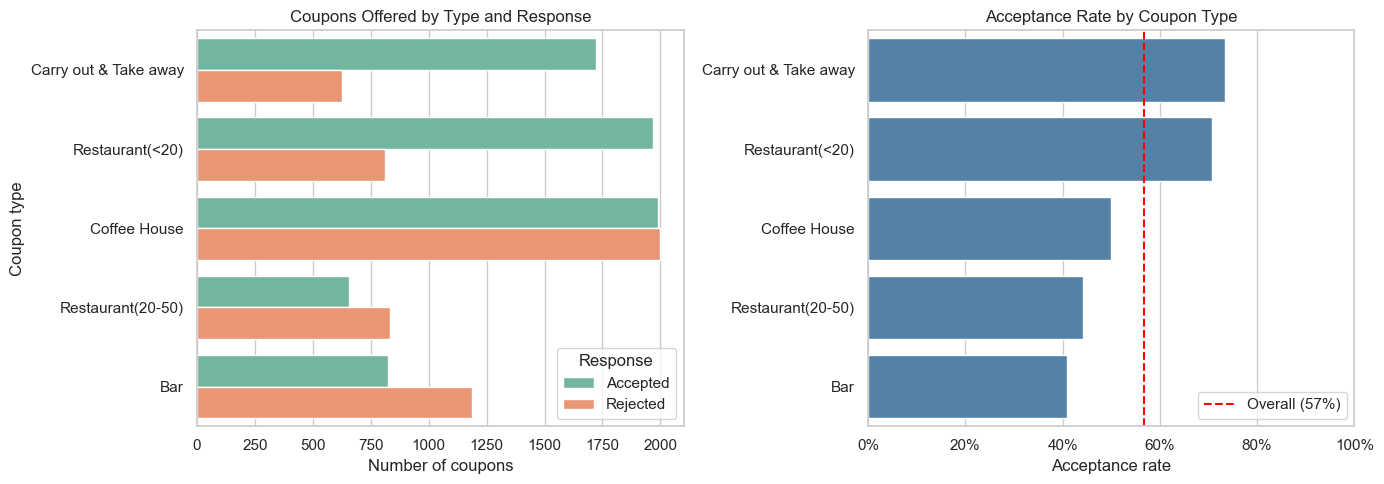

In [17]:
# Order coupon types from most to least accepted so the plots read top-down
coupon_order = data.groupby('coupon')['Y'].mean().sort_values(ascending=False).index

# Readable labels for the 0/1 target
response = data['Y'].map({0: 'Rejected', 1: 'Accepted'})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: how many coupons of each type were accepted vs. rejected
sns.countplot(data=data, y='coupon', hue=response, hue_order=['Accepted', 'Rejected'],
              order=coupon_order, ax=axes[0])
axes[0].set(title='Coupons Offered by Type and Response', xlabel='Number of coupons', ylabel='Coupon type')
axes[0].legend(title='Response')

# Right: acceptance rate per coupon type, compared with the overall rate
sns.barplot(data=data, y='coupon', x='Y', order=coupon_order, errorbar=None,
            color='steelblue', ax=axes[1])
axes[1].axvline(accept_rate, color='red', linestyle='--', label=f'Overall ({accept_rate:.0%})')
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title='Acceptance Rate by Coupon Type', xlabel='Acceptance rate', ylabel='', xlim=(0, 1))
axes[1].legend()

plt.tight_layout()
plt.show()


Based on the above graphs we can say that coupon type matters a lot. **Carry out & Take away (73%)** and **cheap restaurants under \$20 (71%)** are accepted  above the 57% average that we have noticed overall acceptance rates. In the remaing coupon types **Coffee House** splits evenly at 50%, even though it is the most frequently offered coupon (3,989). **Expensive restaurants \$20–50 (44%)** and **Bar (41%)** are accepted least. We can conclude based on this data that coupons are mostly accepted at the cheper locations. Where as these are not accepted where customers are predetermined to spend more like Expensive restuarents and Bars. 

6. Use a histogram to visualize the temperature column.

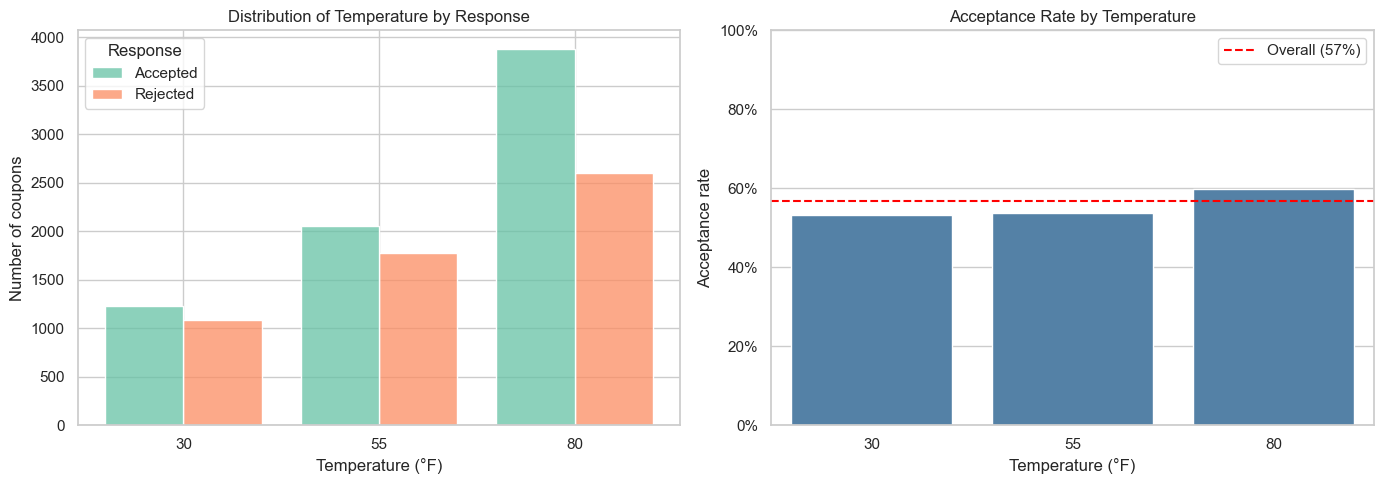

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: histogram of temperature, split by response
# Temperature only takes 30, 55 or 80°F, so the bin edges are set to centre one bar on each value
sns.histplot(data=data, x='temperature', hue=response, hue_order=['Accepted', 'Rejected'],
             bins=[17.5, 42.5, 67.5, 92.5], multiple='dodge', shrink=0.8, ax=axes[0])
axes[0].set(title='Distribution of Temperature by Response', xlabel='Temperature (°F)',
            ylabel='Number of coupons', xticks=[30, 55, 80])
sns.move_legend(axes[0], 'upper left', title='Response')

# Temperature only takes 30, 55 or 80°F, so the bin edges are set to centre one bar on each value
sns.barplot(data=data, x='temperature', y='Y', errorbar=None, color='steelblue', ax=axes[1])
axes[1].axhline(accept_rate, color='red', linestyle='--', label=f'Overall ({accept_rate:.0%})')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title='Acceptance Rate by Temperature', xlabel='Temperature (°F)',
            ylabel='Acceptance rate', ylim=(0, 1))
axes[1].legend()

plt.tight_layout()
plt.show()

Temperature only has three values (30, 55, 80°F), so it behaves more like a category. Most coupons were offered on 80°F days (6,475 of 12,610). Acceptance rises slightly with warmth: **53% at 30°F, 54% at 55°F and 60% at 80°F**. The effect is modest next to coupon type. Temperature is also tied to weather: every 80°F scenario is sunny, and all snowy ones are 30°F. So part of this difference may really be a weather effect.

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [19]:
# Keep only the bar coupons; .copy() makes an independent DataFrame we can safely modify
bar_coupons = data[data['coupon'] == 'Bar'].copy()
bar_coupons.shape

(2010, 25)

2. What proportion of bar coupons were accepted?


In [20]:
# Share of bar coupons accepted
bar_accept_rate = bar_coupons['Y'].mean()
print(f'Bar coupon acceptance rate: {bar_accept_rate:.1%}')

Bar coupon acceptance rate: 41.0%


**Helper used for questions 3–6.** It compares the acceptance rate of drivers matching a condition against everyone else, and adds a chi-square test p-value to judge whether the difference is real.

In [21]:
def compare_groups(df, mask, label):
    """Print and return the acceptance rate for drivers matching `mask` vs. everyone else.

    The p-value comes from a chi-square test: below 0.05 means the difference is
    unlikely to be due to chance.
    """
    group_rate = df.loc[mask, 'Y'].mean()
    other_rate = df.loc[~mask, 'Y'].mean()
    p_value = chi2_contingency(pd.crosstab(mask, df['Y']))[1]
    print(f'{label}\n  Group: {group_rate:.1%} (n={mask.sum()})   '
          f'Others: {other_rate:.1%} (n={(~mask).sum()})   p-value: {p_value:.3g}')
    return {'Group': label, 'Matching drivers': group_rate, 'All others': other_rate}

# Collect each comparison for a summary chart at the end
results = []

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [22]:
# Bar is an ordered category, so <= '1~3' means never, less1 or 1~3
bar_3_or_fewer = bar_coupons['Bar'] <= '1~3'
results.append(compare_groups(bar_coupons, ~bar_3_or_fewer, 'Bar > 3 times/month'))

Bar > 3 times/month
  Group: 76.9% (n=199)   Others: 37.1% (n=1811)   p-value: 4.83e-27


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [23]:
# More than once a month = 1~3, 4~8 or gt8
bar_more_than_once = bar_coupons['Bar'] > 'less1'
over_25 = bar_coupons['age_num'] > 25
results.append(compare_groups(bar_coupons, bar_more_than_once & over_25, 'Bar > 1/month & age > 25'))

Bar > 1/month & age > 25
  Group: 69.5% (n=420)   Others: 33.5% (n=1590)   p-value: 2.02e-40


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [24]:
# Passengers that are not kids, and occupations other than farming/fishing/forestry
no_kid_passenger = bar_coupons['passenger'] != 'Kid(s)'
not_farming = bar_coupons['occupation'] != 'Farming Fishing & Forestry'
results.append(compare_groups(bar_coupons, bar_more_than_once & no_kid_passenger & not_farming,
                              'Bar > 1/month, no kids, not farming'))

Bar > 1/month, no kids, not farming
  Group: 71.3% (n=551)   Others: 29.5% (n=1459)   p-value: 2.29e-64


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [25]:
# Build each condition separately, then test each one and their combination (OR)
not_widowed = bar_coupons['maritalStatus'] != 'Widowed'
under_30 = bar_coupons['age_num'] < 30
cheap_rest_4_plus = bar_coupons['RestaurantLessThan20'] >= '4~8'
low_income = bar_coupons['income'].isin(['Less than $12500', '$12500 - $24999',
                                         '$25000 - $37499', '$37500 - $49999'])

cond_a = bar_more_than_once & no_kid_passenger & not_widowed
cond_b = bar_more_than_once & under_30
cond_c = cheap_rest_4_plus & low_income

results.append(compare_groups(bar_coupons, cond_a, '(a) Bar > 1/month, no kids, not widowed'))
results.append(compare_groups(bar_coupons, cond_b, '(b) Bar > 1/month & under 30'))
results.append(compare_groups(bar_coupons, cond_c, '(c) Cheap restaurants 4+/month & income < $50K'))
results.append(compare_groups(bar_coupons, cond_a | cond_b | cond_c, 'Any of (a), (b) or (c)'))

(a) Bar > 1/month, no kids, not widowed
  Group: 71.3% (n=551)   Others: 29.5% (n=1459)   p-value: 2.29e-64
(b) Bar > 1/month & under 30
  Group: 72.2% (n=345)   Others: 34.5% (n=1665)   p-value: 6.03e-38
(c) Cheap restaurants 4+/month & income < $50K
  Group: 45.3% (n=344)   Others: 40.1% (n=1666)   p-value: 0.0813
Any of (a), (b) or (c)
  Group: 58.9% (n=776)   Others: 29.7% (n=1234)   p-value: 5.09e-38


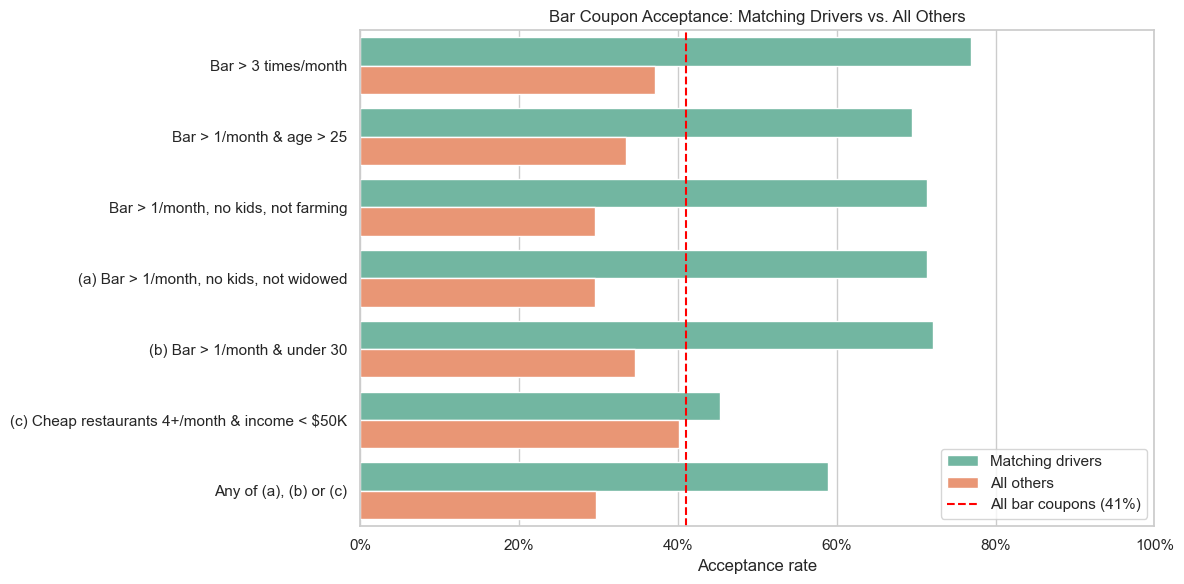

In [26]:
# Turn the collected results into long format: one row per (group, who) pair for seaborn
summary = pd.DataFrame(results).melt(id_vars='Group', var_name='Who', value_name='Acceptance rate')

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=summary, y='Group', x='Acceptance rate', hue='Who', ax=ax)
ax.axvline(bar_accept_rate, color='red', linestyle='--', label=f'All bar coupons ({bar_accept_rate:.0%})')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Bar Coupon Acceptance: Matching Drivers vs. All Others',
       xlabel='Acceptance rate', ylabel='', xlim=(0, 1))
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

**Hypothesis: who accepts bar coupons?**

Drivers who  go to bars regularly are far more likely to accept coupons. Going more than 3 times a month raises acceptance to **77%**, against 37% for everyone else. Combining "more than once a month" with being under 30 (72%), or with having no kids in the car, keeps acceptance high, while the remaining drivers fall to about 30%. These differences are statistically significant (p < 0.001).

By contrast, frequent cheap-restaurant diners with income under $50K accept at only 45%, close to the average and not significant (p ≈ 0.08). Income and dining habits alone don't predict bar acceptance.

In summary bar coupons work for existing, younger bar-goers driving without children. Past bar-going habit is the strongest single signal.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

**Problem: who accepts Coffee House coupons?**

Coffee House is the most frequently offered coupon (3,989 offers), yet only about half are accepted. The goal is to find which driver characteristics and driving situations separate accepters from rejecters, so coupons can be targeted where they are likely to be used.

In [27]:
# Keep only Coffee House coupons
coffee = data[data['coupon'] == 'Coffee House'].copy()
coffee_accept_rate = coffee['Y'].mean()
print(f'Coffee House coupons: {len(coffee)}   Acceptance rate: {coffee_accept_rate:.1%}')

# Combine the two distance flags into one readable driving-time column
coffee['drive_time'] = np.select(
    [coffee['toCoupon_GEQ25min'] == 1, coffee['toCoupon_GEQ15min'] == 1],
    ['25+ min', '15-25 min'], default='< 15 min')

# Short income labels in their natural order (the '$' signs would be read as maths formatting in plot labels)
income_order = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999', '$50000 - $62499',
                '$62500 - $74999', '$75000 - $87499', '$87500 - $99999', '$100000 or More']
income_labels = ['<12.5K', '12.5-25K', '25-37.5K', '37.5-50K', '50-62.5K', '62.5-75K', '75-87.5K', '87.5-100K', '100K+']
coffee['income_band'] = coffee['income'].map(dict(zip(income_order, income_labels)))

Coffee House coupons: 3989   Acceptance rate: 49.9%


In [31]:
def plot_acceptance(df, col, ax, title, order=None, baseline=None):
    """Bar chart of acceptance rate for each value of `col`, labelled with percentages."""
    sns.barplot(data=df, x=col, y='Y', order=order, errorbar=None, color='steelblue', ax=ax)
    ax.bar_label(ax.containers[0], fmt='{:.0%}', padding=2)
    if baseline is not None:
        ax.axhline(baseline, color='red', linestyle='--', label=f'All coffee coupons ({baseline:.0%})')
        ax.legend(loc='upper left')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=title, xlabel='', ylabel='Acceptance rate', ylim=(0, 1))

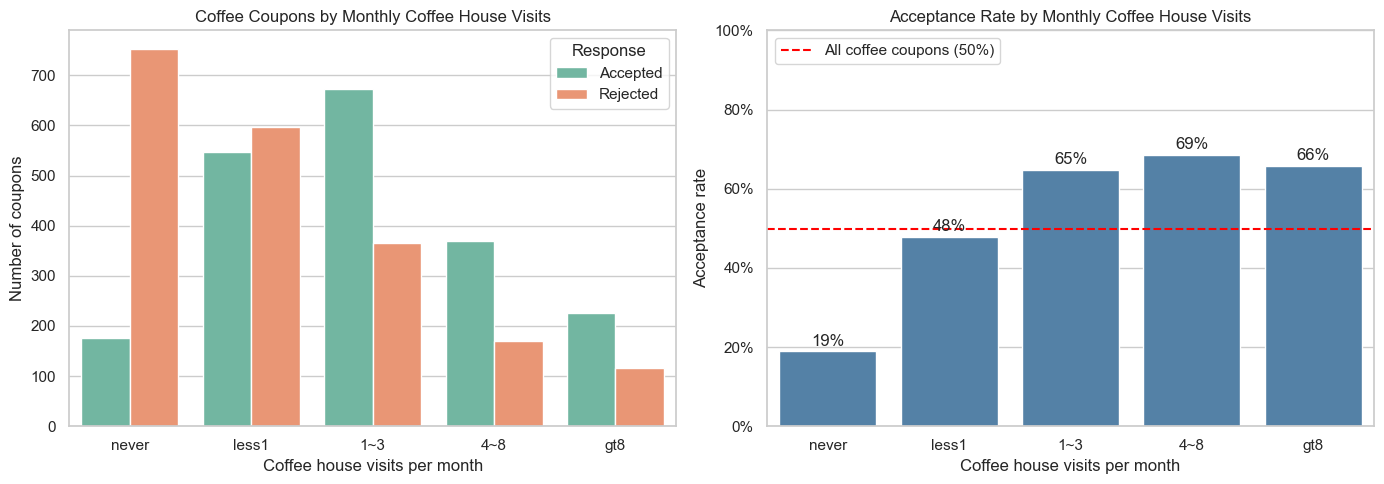

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: accepted vs. rejected counts by how often the driver visits coffee houses
sns.countplot(data=coffee, x='CoffeeHouse', hue=coffee['Y'].map({0: 'Rejected', 1: 'Accepted'}),
              hue_order=['Accepted', 'Rejected'], ax=axes[0])
axes[0].set(title='Coffee Coupons by Monthly Coffee House Visits',
            xlabel='Coffee house visits per month', ylabel='Number of coupons')
axes[0].legend(title='Response')

# Right: acceptance rate for each visit frequency
plot_acceptance(coffee, 'CoffeeHouse', axes[1], 'Acceptance Rate by Monthly Coffee House Visits',
                baseline=coffee_accept_rate)
axes[1].set_xlabel('Coffee house visits per month')

plt.tight_layout()
plt.show()

Visit habit is the strongest signal. Drivers who **never** go to coffee houses accept only **19%** of coffee coupons, while those who go **1 or more times a month** accept **65–69%**.

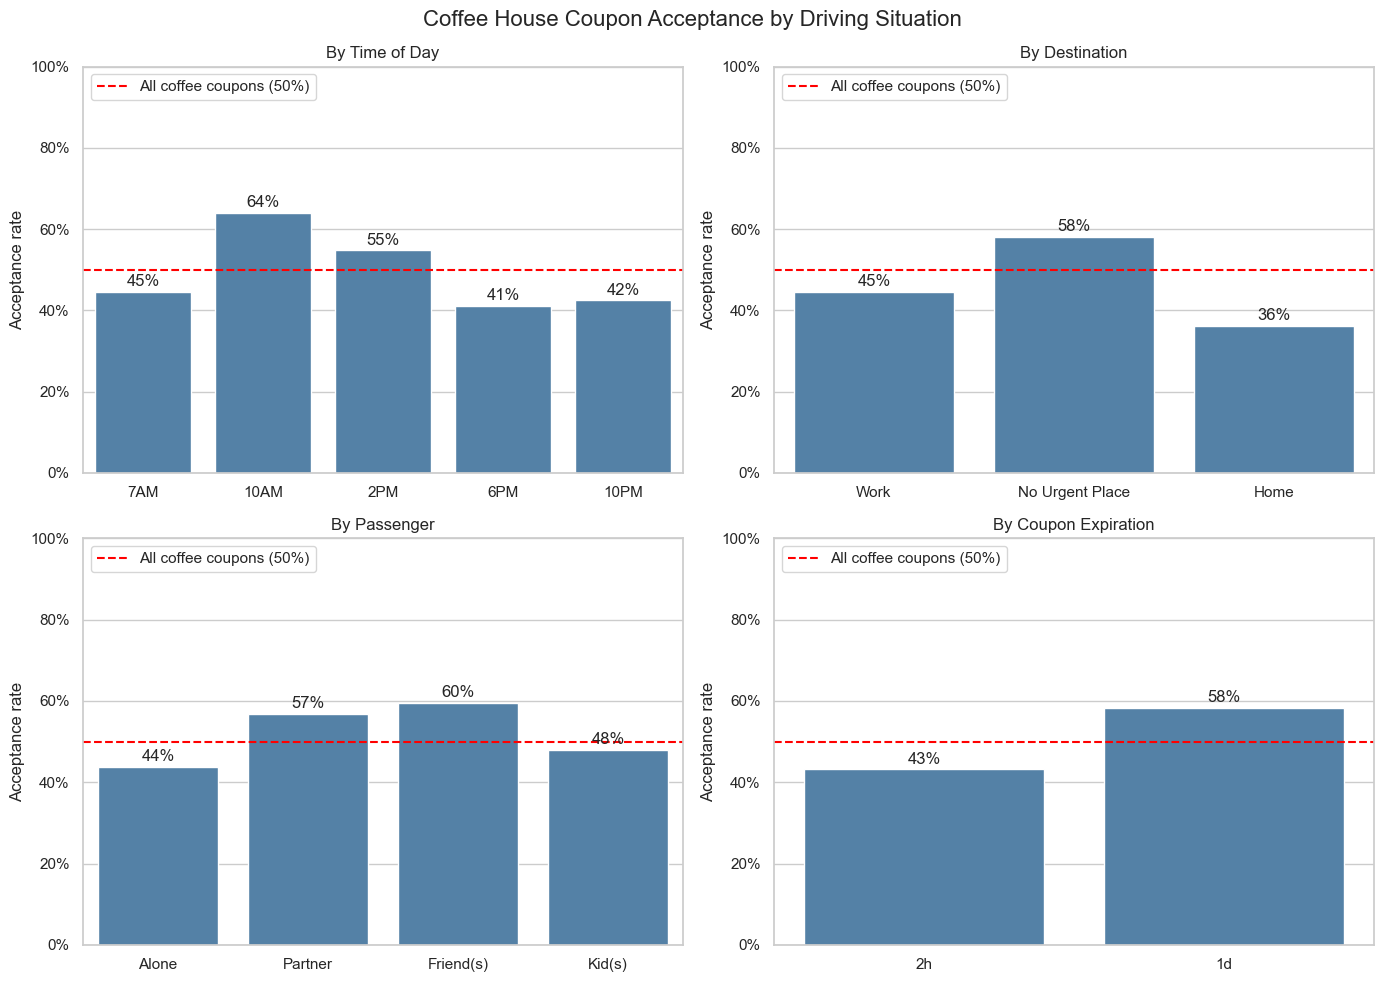

In [30]:
# Acceptance rate across the driving-situation factors
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plot_acceptance(coffee, 'time', axes[0, 0], 'By Time of Day',
                order=['7AM', '10AM', '2PM', '6PM', '10PM'], baseline=coffee_accept_rate)
plot_acceptance(coffee, 'destination', axes[0, 1], 'By Destination',
                order=['Work', 'No Urgent Place', 'Home'], baseline=coffee_accept_rate)
plot_acceptance(coffee, 'passenger', axes[1, 0], 'By Passenger',
                order=['Alone', 'Partner', 'Friend(s)', 'Kid(s)'], baseline=coffee_accept_rate)
plot_acceptance(coffee, 'expiration', axes[1, 1], 'By Coupon Expiration',
                order=['2h', '1d'], baseline=coffee_accept_rate)

fig.suptitle('Coffee House Coupon Acceptance by Driving Situation', fontsize=16)
plt.tight_layout()
plt.show()

Situation matters too. Acceptance peaks at **10AM (64%)** and **2PM (55%)**, when drivers have **no urgent destination (58%)**, travel **with friends (60%) or a partner (57%)**, and the coupon lasts **1 day (58% vs. 43% for 2 hours)**. Drivers heading **home (36%)** or out in the evening (6PM 41%) are the least interested.